# EN4554 Assignment 2 - Tasks 3 and 4: Regularization, residual connections, and the best CNN

- **(a)** A small CNN with batch norm trained on only **5k** training images: baseline, weight decay, dropout, flip+crop, cutout, mixup and all combined (cutout, mixup and flip+crop are implemented by hand). Train accuracy, validation accuracy and the gap are tabulated and the curves plotted.
- **(b)** CIFAR-style **plain** vs **residual** networks of depth 6n+2 (8, 20, 56). The two families differ *only* in the shortcut; training loss vs epoch is plotted and explained.

Data split, seed and normalisation are identical to Tasks 1 and 2 (45k train / 5k validation, statistics from the training split only). The test set is **not used in Task 3**; it is used exactly once, at the very end of Task 4.
- **Task 4 (optional)** Best CNN with at most 500k parameters and at most 20 epochs: learning rate / weight decay tuned on the validation split, an 8-variant ablation, and a single test-set evaluation of the final model (last section of this notebook).


In [1]:
import math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
print('Using device:', device)

Using device: cuda


## Data: CIFAR-10 (45k train / 5k val), same split as Tasks 1-2

In [2]:
raw = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X_all = torch.from_numpy(raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()
y_all = torch.tensor(raw.targets, dtype=torch.long)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
del X_all

mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)       # training-split statistics only
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
X_tr, X_va = ((X_tr - mean) / std).to(device), ((X_va - mean) / std).to(device)
y_tr, y_va = y_tr.to(device), y_va.to(device)
print('Train:', tuple(X_tr.shape), '| Val:', tuple(X_va.shape))

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct  += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

100%|██████████| 170M/170M [45:12<00:00, 62.9kB/s]


Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)


## Task 3(a) - Regularisation with only 5k training images

5k subset class counts: [530, 483, 478, 478, 493, 497, 517, 518, 511, 495]


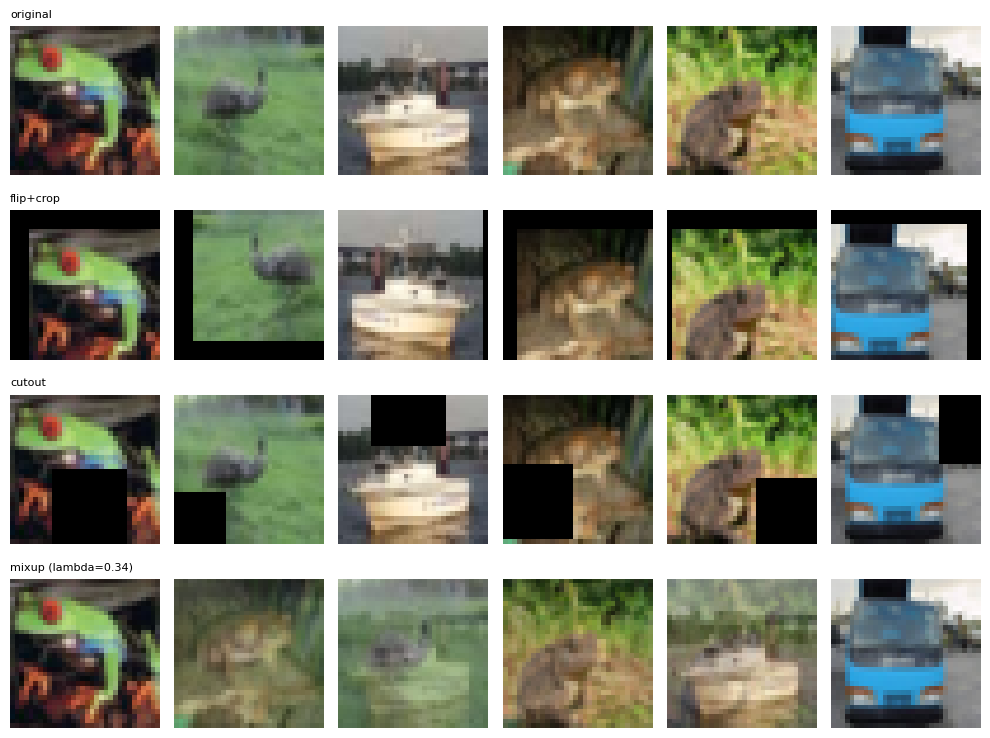

In [3]:
N_SMALL = 5000
X5, y5 = X_tr[:N_SMALL], y_tr[:N_SMALL]
print('5k subset class counts:', torch.bincount(y5.cpu(), minlength=10).tolist())

# ---------- augmentations, implemented by hand (batched, on the device) ----------
def random_flip(x):
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    N, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))                                      # zero padding
    oy = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)[None, :]           # (N,H)
    cols = ox[:, None] + torch.arange(W, device=x.device)[None, :]           # (N,W)
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows[:, None, :, None], cols[:, None, None, :]]

def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device); cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :]; xs = torch.arange(W, device=x.device)[None, :]
    my = (ys >= (cy - size // 2)[:, None]) & (ys < (cy + size // 2)[:, None])   # (N,H)
    mx = (xs >= (cx - size // 2)[:, None]) & (xs < (cx + size // 2)[:, None])   # (N,W)
    mask = (my[:, :, None] & mx[:, None, :])[:, None]                          # (N,1,H,W)
    return x.masked_fill(mask, 0.0)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    j = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[j], y, y[j], lam

# quick visual check of the augmentations on real (un-normalised) images
set_seed(0)
vis = (X5[:6] * std.to(device) + mean.to(device)).clamp(0, 1)
mx_img, _, _, lam_vis = mixup(vis, y5[:6])
rows = {'original': vis, 'flip+crop': random_crop(random_flip(vis)), 'cutout': cutout(vis), f'mixup (lambda={lam_vis:.2f})': mx_img}
fig, ax = plt.subplots(len(rows), 6, figsize=(10, 1.9 * len(rows)))
for r, (name, imgs) in enumerate(rows.items()):
    for c in range(6):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis('off')
    ax[r, 0].set_title(name, fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In [4]:
class SmallBNCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), p_drop=0.0, n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for c in channels:
            layers += [nn.Conv2d(cin, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            cin = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(cin, n_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x): return self.head(self.features(x))

print('SmallBNCNN parameters:', sum(p.numel() for p in SmallBNCNN().parameters()))

EPOCHS_A, SEEDS_A, BS_A, LR_A = 60, (0, 1, 2), 128, 0.05
CONFIGS = {
    'baseline':      dict(),
    'weight decay':  dict(wd=5e-4),
    'dropout':       dict(drop=0.5),
    'flip+crop':     dict(flipcrop=True),
    'cutout':        dict(cutout=True),
    'mixup':         dict(mixup=True),
    'all combined':  dict(wd=5e-4, drop=0.5, flipcrop=True, cutout=True, mixup=True),
}

def train_small(cfg, seed, epochs=EPOCHS_A, bs=BS_A, lr=LR_A):
    set_seed(seed)
    model = SmallBNCNN(p_drop=cfg.get('drop', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    N = len(X5); hist = dict(tr_acc=[], va_acc=[], tr_loss=[], va_loss=[])
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device)
        for i in range(0, N - bs + 1, bs):                           # drop the incomplete last batch (BN)
            idx = order[i:i + bs]; x, y = X5[idx], y5[idx]
            if cfg.get('flipcrop'): x = random_crop(random_flip(x))
            if cfg.get('cutout'):   x = cutout(x)
            opt.zero_grad(set_to_none=True)
            if cfg.get('mixup'):
                x, ya, yb, lam = mixup(x, y)
                out = model(x); loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb)
            else:
                loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
        sched.step()
        tl, ta = evaluate(model, X5, y5)                             # CLEAN train metrics, eval mode
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tl); hist['tr_acc'].append(ta); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

SmallBNCNN parameters: 288746


In [5]:
results_a = {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    for seed in SEEDS_A:
        results_a[(name, seed)] = h = train_small(cfg, seed)
        print(f"{name:<13} seed={seed}  train acc {h['tr_acc'][-1]:6.2f}%  val acc {h['va_acc'][-1]:6.2f}%  "
              f"gap {h['tr_acc'][-1] - h['va_acc'][-1]:6.2f}  [{time.time() - t0:.0f}s]")

baseline      seed=0  train acc 100.00%  val acc  68.76%  gap  31.24  [76s]
baseline      seed=1  train acc 100.00%  val acc  69.34%  gap  30.66  [162s]
baseline      seed=2  train acc 100.00%  val acc  67.20%  gap  32.80  [249s]
weight decay  seed=0  train acc 100.00%  val acc  67.66%  gap  32.34  [336s]
weight decay  seed=1  train acc 100.00%  val acc  68.02%  gap  31.98  [422s]
weight decay  seed=2  train acc 100.00%  val acc  68.38%  gap  31.62  [510s]
dropout       seed=0  train acc 100.00%  val acc  67.30%  gap  32.70  [597s]
dropout       seed=1  train acc 100.00%  val acc  65.84%  gap  34.16  [685s]
dropout       seed=2  train acc 100.00%  val acc  66.24%  gap  33.76  [772s]
flip+crop     seed=0  train acc  97.58%  val acc  74.20%  gap  23.38  [859s]
flip+crop     seed=1  train acc  97.94%  val acc  75.48%  gap  22.46  [947s]
flip+crop     seed=2  train acc  97.64%  val acc  74.96%  gap  22.68  [1034s]
cutout        seed=0  train acc 100.00%  val acc  70.40%  gap  29.60  [1121s

configuration      train acc (%)       val acc (%)   gap (train - val)   best-epoch val acc  final val loss
baseline           100.00 ± 0.00      68.43 ± 0.90        31.57 ± 0.90                68.68           1.316
weight decay       100.00 ± 0.00      68.02 ± 0.29        31.98 ± 0.29                68.50           1.182
dropout            100.00 ± 0.00      66.46 ± 0.62        33.54 ± 0.62                66.83           1.464
flip+crop           97.72 ± 0.16      74.88 ± 0.53        22.84 ± 0.39                75.17           0.859
cutout             100.00 ± 0.00      70.75 ± 0.37        29.25 ± 0.37                70.99           1.155
mixup              100.00 ± 0.00      68.63 ± 0.07        31.37 ± 0.07                68.95           0.977
all combined        77.32 ± 0.53      68.64 ± 0.23         8.68 ± 0.37                69.02           0.876


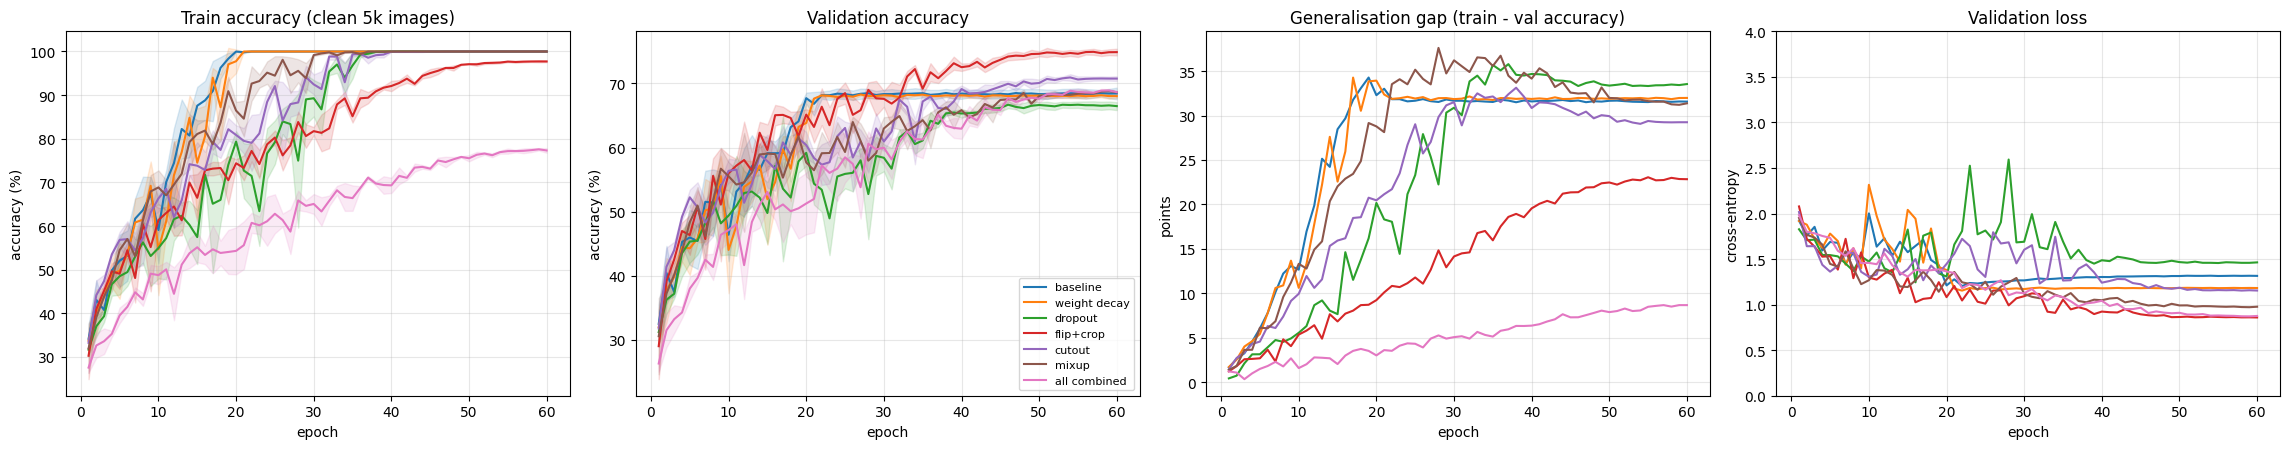

In [6]:
def stack(name, key): return np.array([results_a[(name, s)][key] for s in SEEDS_A])     # (seeds, epochs)

print(f"{'configuration':<14}{'train acc (%)':>18}{'val acc (%)':>18}{'gap (train - val)':>20}{'best-epoch val acc':>21}{'final val loss':>16}")
for name in CONFIGS:
    tr, va = stack(name, 'tr_acc')[:, -1], stack(name, 'va_acc')[:, -1]
    best = stack(name, 'va_acc').max(1); vl = stack(name, 'va_loss')[:, -1]
    print(f'{name:<14}{tr.mean():>11.2f} ± {tr.std():<4.2f}{va.mean():>11.2f} ± {va.std():<4.2f}{(tr - va).mean():>13.2f} ± {(tr - va).std():<4.2f}{best.mean():>21.2f}{vl.mean():>16.3f}')

ep = np.arange(1, EPOCHS_A + 1)
cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(1, 4, figsize=(23, 4.6))
for k, name in enumerate(CONFIGS):
    for a, key in zip(ax[:2], ('tr_acc', 'va_acc')):
        m, s = stack(name, key).mean(0), stack(name, key).std(0)
        a.plot(ep, m, color=cmap(k), label=name); a.fill_between(ep, m - s, m + s, color=cmap(k), alpha=.15)
    ax[2].plot(ep, (stack(name, 'tr_acc') - stack(name, 'va_acc')).mean(0), color=cmap(k), label=name)
    ax[3].plot(ep, stack(name, 'va_loss').mean(0), color=cmap(k), label=name)
ax[0].set(title='Train accuracy (clean 5k images)', xlabel='epoch', ylabel='accuracy (%)')
ax[1].set(title='Validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
ax[2].set(title='Generalisation gap (train - val accuracy)', xlabel='epoch', ylabel='points')
ax[3].set(title='Validation loss', xlabel='epoch', ylabel='cross-entropy', ylim=(0, 4))
for a in ax: a.grid(alpha=.3)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Task 3(b) - Plain vs residual networks of depth 6n+2 (8, 20, 56)

In [7]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin
    def shortcut(self, x):
        if self.stride == 1 and self.extra == 0: return x                         # identity
        return F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))   # option A
    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual: out = out + self.shortcut(x)                             # the ONLY difference
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        blocks, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for b in range(n):
                blocks.append(Block(cin, cout, stride if b == 0 else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

def make(n, residual):
    set_seed(0); return CifarNet(n, residual).to(device)         # same seed -> identical initial weights for both families

# sanity checks: depth = number of weight layers, equal parameter counts, identical initial weights
for n in (1, 3, 9):
    mp, mr = make(n, False), make(n, True)
    depth = 1 + sum(isinstance(m, nn.Conv2d) for m in mp.blocks.modules()) + 1
    same_init = all(torch.equal(a, b) for a, b in zip(mp.parameters(), mr.parameters()))
    print(f'n={n}: depth {depth} (6n+2 = {6 * n + 2}) | params plain {sum(p.numel() for p in mp.parameters()):,} '
          f'= residual {sum(p.numel() for p in mr.parameters()):,} | identical initial weights: {same_init}')

n=1: depth 8 (6n+2 = 8) | params plain 75,290 = residual 75,290 | identical initial weights: True
n=3: depth 20 (6n+2 = 20) | params plain 269,722 = residual 269,722 | identical initial weights: True
n=9: depth 56 (6n+2 = 56) | params plain 853,018 = residual 853,018 | identical initial weights: True


In [8]:
# Diagnostic at initialisation: gradient norm of the stem conv vs the last block's second conv, one minibatch
set_seed(1); xb, yb = X_tr[:256], y_tr[:256]
print(f"{'depth':>6}{'family':>10}{'|grad stem conv|':>20}{'|grad last conv|':>20}{'ratio first/last':>20}")
for n in (1, 3, 9):
    for residual in (False, True):
        m = make(n, residual); m.train(); m.zero_grad()
        F.cross_entropy(m(xb), yb).backward()
        g_first = m.stem[0].weight.grad.norm().item(); g_last = m.blocks[-1].conv2.weight.grad.norm().item()
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{g_first:>20.4f}{g_last:>20.4f}{g_first / g_last:>20.3f}")

 depth    family    |grad stem conv|    |grad last conv|    ratio first/last
     8     plain              0.2276              0.4061               0.560
     8  residual              0.2795              0.5443               0.513
    20     plain              0.7464              0.3175               2.351
    20  residual              0.8209              1.2047               0.681
    56     plain            377.3405              0.7394             510.301
    56  residual              1.5321              0.7539               2.032


In [10]:
EPOCHS_B, BS_B, LR_B, WD_B, DEPTHS = 20, 128, 0.1, 1e-4, (1, 3, 9)       # n = 1, 3, 9  ->  depth 8, 20, 56

def train_cifarnet(n, residual, epochs=EPOCHS_B, bs=BS_B):
    model = make(n, residual)
    opt = torch.optim.SGD(model.parameters(), lr=LR_B, momentum=0.9, weight_decay=WD_B)
    N = len(X_tr); steps_per_ep = N // bs; total = epochs * steps_per_ep; warm = steps_per_ep
    lr_at = lambda t: LR_B * (t + 1) / warm if t < warm else 0.5 * LR_B * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
    hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False); step = 0
    set_seed(0)                                                      # identical minibatch order for plain and residual
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, steps_per_ep * bs, bs):
            for g in opt.param_groups: g['lr'] = lr_at(step)
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx]); loss.backward(); opt.step()
            run += loss.detach() * bs; step += 1
        tr = run.item() / (steps_per_ep * bs)
        if not math.isfinite(tr):
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

results_b = {}
t0 = time.time()
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)] = train_cifarnet(n, residual)
        print(f"depth {6 * n + 2:>2} {'residual' if residual else 'plain   '}  final train loss {h['tr_loss'][-1]:.4f}  "
              f"final val acc {h['va_acc'][-1]:.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time() - t0:.0f}s]")

depth  8 plain     final train loss 0.1901  final val acc 79.94%   [89s]
depth  8 residual  final train loss 0.1896  final val acc 79.08%   [181s]
depth 20 plain     final train loss 0.0303  final val acc 82.64%   [431s]
depth 20 residual  final train loss 0.0050  final val acc 83.36%   [690s]
depth 56 plain     final train loss 0.3724  final val acc 66.24%   [1421s]
depth 56 residual  final train loss 0.0013  final val acc 83.88%   [2185s]


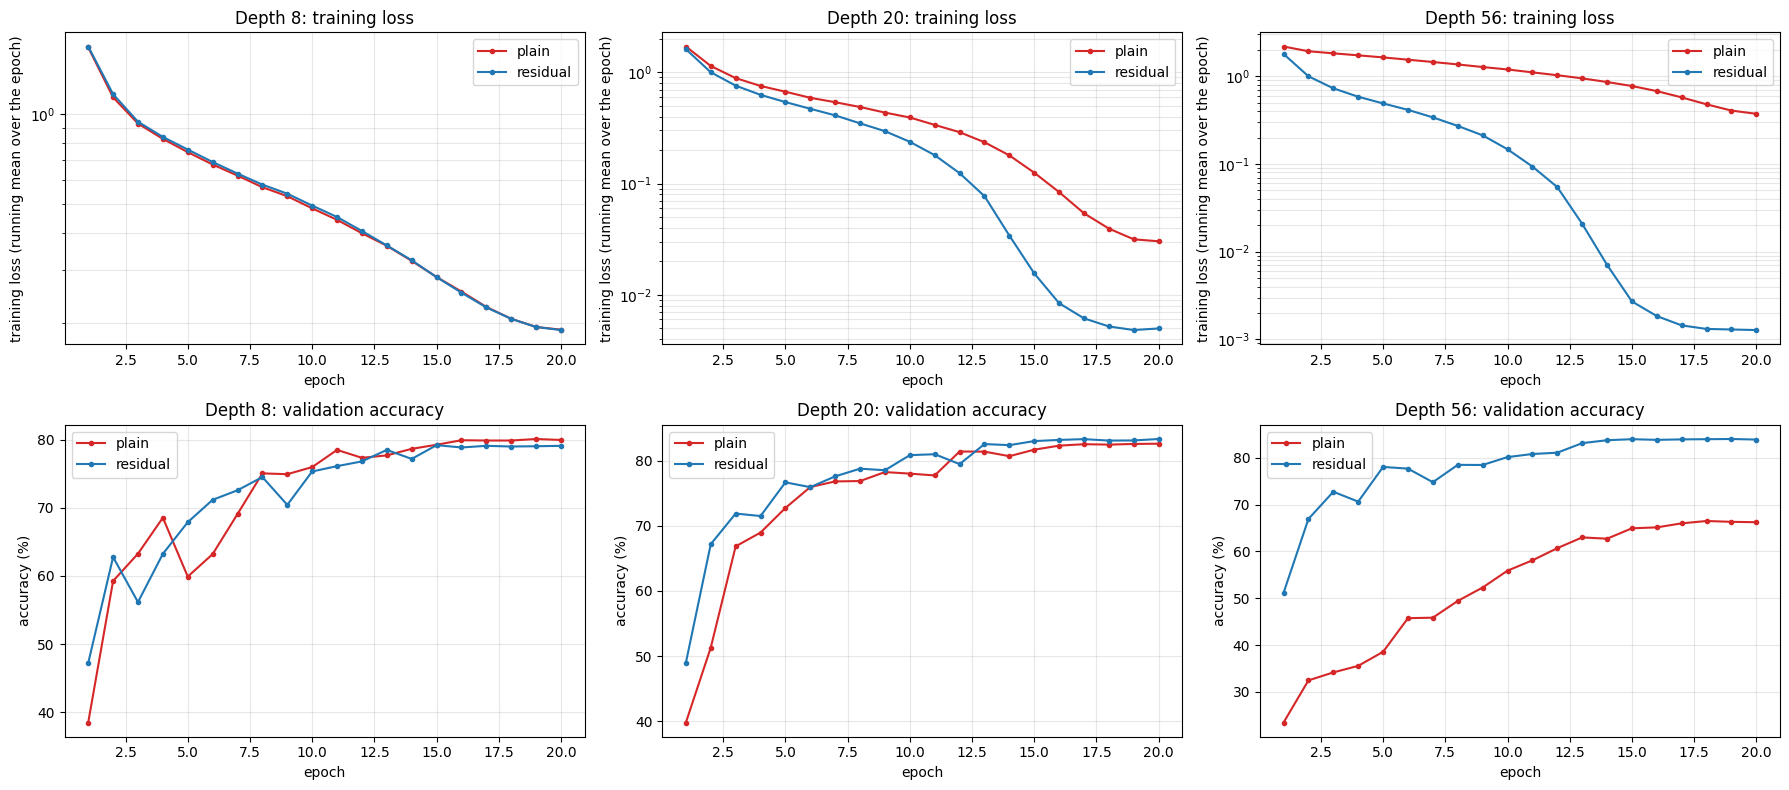

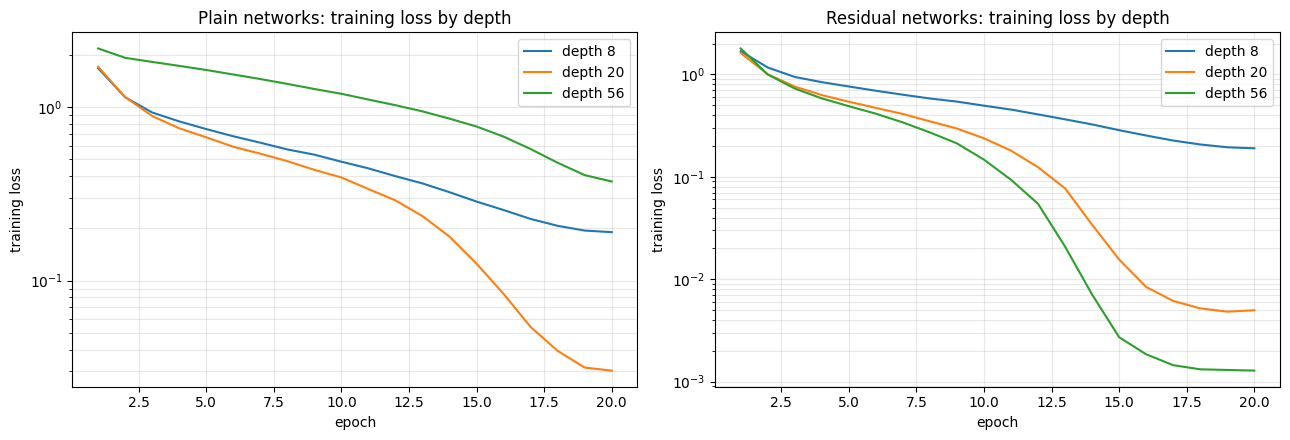

 depth    family    params  train loss @ep1  train loss @ep5  final train loss  final val acc (%)
     8     plain    75,290           1.6736           0.7465            0.1901              79.94
     8  residual    75,290           1.6842           0.7616            0.1896              79.08
    20     plain   269,722           1.7075           0.6696            0.0303              82.64
    20  residual   269,722           1.6167           0.5404            0.0050              83.36
    56     plain   853,018           2.1769           1.6359            0.3724              66.24
    56  residual   853,018           1.7910           0.4888            0.0013              83.88


In [11]:
ep = np.arange(1, EPOCHS_B + 1)
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for c, n in enumerate(DEPTHS):
    for residual, col in ((False, 'tab:red'), (True, 'tab:blue')):
        h = results_b[(n, residual)]; lab = 'residual' if residual else 'plain'
        ax[0, c].plot(ep, h['tr_loss'], 'o-', ms=3, color=col, label=lab)
        ax[1, c].plot(ep, h['va_acc'], 'o-', ms=3, color=col, label=lab)
    ax[0, c].set(title=f'Depth {6 * n + 2}: training loss', xlabel='epoch', ylabel='training loss (running mean over the epoch)', yscale='log')
    ax[1, c].set(title=f'Depth {6 * n + 2}: validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
    for r in (0, 1): ax[r, c].grid(alpha=.3, which='both'); ax[r, c].legend()
plt.tight_layout(); plt.show()

# all depths together per family: the degradation problem shows as plain-56 above plain-20
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, residual in zip(ax, (False, True)):
    for n in DEPTHS: a.plot(ep, results_b[(n, residual)]['tr_loss'], label=f'depth {6 * n + 2}')
    a.set(title=f"{'Residual' if residual else 'Plain'} networks: training loss by depth", xlabel='epoch', ylabel='training loss', yscale='log')
    a.grid(alpha=.3, which='both'); a.legend()
plt.tight_layout(); plt.show()

print(f"{'depth':>6}{'family':>10}{'params':>10}{'train loss @ep1':>17}{'train loss @ep5':>17}{'final train loss':>18}{'final val acc (%)':>19}")
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)]; P = sum(p.numel() for p in make(n, residual).parameters())
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{P:>10,}{h['tr_loss'][0]:>17.4f}{h['tr_loss'][4]:>17.4f}{h['tr_loss'][-1]:>18.4f}{h['va_acc'][-1]:>19.2f}")

# Task 4: Design the best CNN (at most 500k parameters, at most 20 epochs)

In [12]:
# ===================== Task 4: model, configuration and training function =====================
MAX_PARAMS, MAX_EPOCHS = 500_000, 20
USE_AMP = device.type == 'cuda'                      # fp16 mixed precision on the GPU only
try:    make_scaler = lambda: torch.amp.GradScaler('cuda', enabled=USE_AMP)
except AttributeError: make_scaler = lambda: torch.cuda.amp.GradScaler(enabled=USE_AMP)

def count_params(m): return sum(p.numel() for p in m.parameters())

class ResNetW(nn.Module):
    '''CIFAR ResNet of depth 6n+2 with configurable stage widths. Reuses Block from Task 3(b) (option-A shortcut).
    residual=False gives the plain network (identical parameters, no shortcut).'''
    def __init__(self, n=3, widths=(20, 40, 80), residual=True, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, cin = [], widths[0]
        for si, cout in enumerate(widths):
            for b in range(n):
                blocks.append(Block(cin, cout, 2 if (b == 0 and si > 0) else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

# parameter budget check for a few candidate sizes (depth 20 unless stated)
for n, w in [(3, (16, 32, 64)), (3, (20, 40, 80)), (3, (22, 44, 88)), (4, (18, 36, 72)), (4, (20, 40, 80))]:
    p = count_params(ResNetW(n, w))
    print(f'depth {6*n+2:>2}, widths {w}: {p:>9,} parameters  ->  {"within budget" if p <= MAX_PARAMS else "OVER the 500k budget"}')

BASE = dict(n=3, widths=(20, 40, 80), residual=True, opt='sgd', lr=0.1, wd=5e-4,
            flipcrop=True, cutout=8, ls=0.1)          # cutout = square side in pixels (0 = off); ls = label smoothing

def train_net(cfg, seed, epochs=MAX_EPOCHS, bs=128, verbose=False):
    '''Train on the 45k split. Returns (history, final-epoch state_dict on CPU). Validation is measured after every epoch.'''
    assert epochs <= MAX_EPOCHS, 'at most 20 epochs allowed'
    set_seed(seed)
    model = ResNetW(cfg['n'], cfg['widths'], cfg['residual']).to(device).to(memory_format=torch.channels_last)
    n_par = count_params(model); assert n_par <= MAX_PARAMS, f'{n_par} parameters > {MAX_PARAMS}'
    if cfg['opt'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    else:
        opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    scaler = make_scaler()
    N = len(X_tr); steps_per_ep = N // bs; total = epochs * steps_per_ep; warm = steps_per_ep      # 1 warm-up epoch, then cosine to 0
    lr_at = lambda t: cfg['lr'] * (t + 1) / warm if t < warm else 0.5 * cfg['lr'] * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
    hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False, params=n_par); step = 0
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, steps_per_ep * bs, bs):
            for g in opt.param_groups: g['lr'] = lr_at(step)
            idx = order[i:i + bs]; x, y = X_tr[idx], y_tr[idx]
            if cfg['flipcrop']: x = random_crop(random_flip(x))          # hand-written augmentations from Task 3(a)
            if cfg['cutout']:   x = cutout(x, size=cfg['cutout'])
            x = x.contiguous(memory_format=torch.channels_last)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                loss = F.cross_entropy(model(x), y, label_smoothing=cfg['ls'])
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.detach() * bs; step += 1
        tr = run.item() / (steps_per_ep * bs)
        if not math.isfinite(tr):                                      # diverged: stop and count as chance accuracy
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f'    epoch {ep+1:2d}/{epochs}  train loss {tr:.4f}  val loss {vl:.4f}  val acc {va:.2f}%')
    return hist, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

depth 20, widths (16, 32, 64):   269,722 parameters  ->  within budget
depth 20, widths (20, 40, 80):   420,670 parameters  ->  within budget
depth 20, widths (22, 44, 88):   508,672 parameters  ->  OVER the 500k budget
depth 26, widths (18, 36, 72):   463,996 parameters  ->  within budget
depth 26, widths (20, 40, 80):   572,430 parameters  ->  OVER the 500k budget


In [13]:
TUNE_SEED = 0
GRID = [(lr, wd) for lr in (0.05, 0.1, 0.2) for wd in (5e-4, 1e-3)]
tune, tune_sd = {}, {}
t0 = time.time()
for lr, wd in GRID:
    cfg = {**BASE, 'lr': lr, 'wd': wd}
    tune[(lr, wd)], tune_sd[(lr, wd)] = train_net(cfg, TUNE_SEED)
    h = tune[(lr, wd)]
    print(f"lr={lr:<5g} wd={wd:<7g}  final train loss {h['tr_loss'][-1]:.4f}  final val acc {h['va_acc'][-1]:.2f}%  "
          f"best-epoch val acc {max(h['va_acc']):.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time()-t0:.0f}s]")

best_key = max(tune, key=lambda k: tune[k]['va_acc'][-1])
best_lr, best_wd = best_key
FINAL = {**BASE, 'lr': best_lr, 'wd': best_wd}
print(f"\nSelected on validation: lr={best_lr:g}, wd={best_wd:g}  ->  {tune[best_key]['va_acc'][-1]:.2f}%   "
      f"({tune[best_key]['params']:,} parameters, {MAX_EPOCHS} epochs)")

lr=0.05  wd=0.0005   final train loss 0.7356  final val acc 88.92%  best-epoch val acc 89.12%   [136s]
lr=0.05  wd=0.001    final train loss 0.7096  final val acc 90.10%  best-epoch val acc 90.18%   [271s]
lr=0.1   wd=0.0005   final train loss 0.7005  final val acc 90.04%  best-epoch val acc 90.18%   [406s]
lr=0.1   wd=0.001    final train loss 0.6941  final val acc 91.20%  best-epoch val acc 91.36%   [541s]
lr=0.2   wd=0.0005   final train loss 0.6882  final val acc 90.88%  best-epoch val acc 90.92%   [676s]
lr=0.2   wd=0.001    final train loss 0.7133  final val acc 90.52%  best-epoch val acc 90.52%   [811s]

Selected on validation: lr=0.1, wd=0.001  ->  91.20%   (420,670 parameters, 20 epochs)


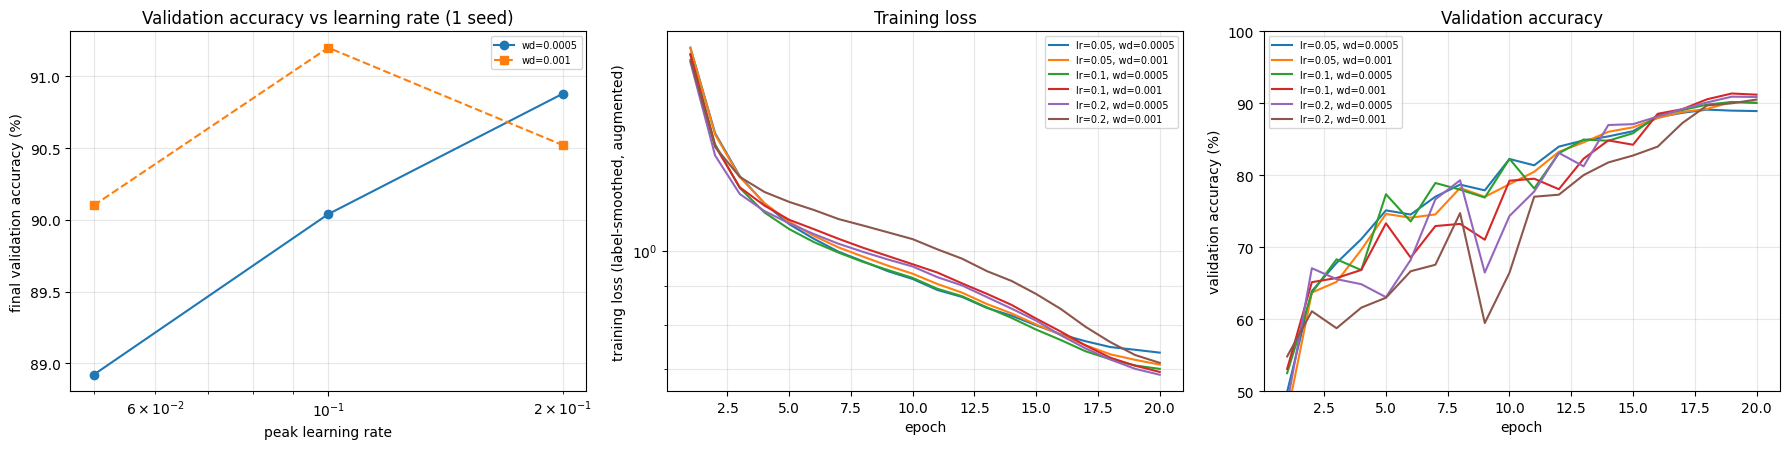

    lr       wd  final train loss  final val acc (%)  best-epoch val acc (%)
  0.05   0.0005            0.7356              88.92                   89.12
  0.05    0.001            0.7096              90.10                   90.18
   0.1   0.0005            0.7005              90.04                   90.18
   0.1    0.001            0.6941              91.20                   91.36   <- selected
   0.2   0.0005            0.6882              90.88                   90.92
   0.2    0.001            0.7133              90.52                   90.52


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for wd, mk in zip((5e-4, 1e-3), ('o-', 's--')):
    lrs = [lr for lr, w in GRID if w == wd]
    ax[0].plot(lrs, [tune[(lr, wd)]['va_acc'][-1] for lr in lrs], mk, label=f'wd={wd:g}')
ax[0].set(xscale='log', xlabel='peak learning rate', ylabel='final validation accuracy (%)', title='Validation accuracy vs learning rate (1 seed)')
ep = np.arange(1, MAX_EPOCHS + 1)
for (lr, wd), h in tune.items():
    ax[1].plot(ep, h['tr_loss'], label=f'lr={lr:g}, wd={wd:g}'); ax[2].plot(ep, h['va_acc'], label=f'lr={lr:g}, wd={wd:g}')
ax[1].set(xlabel='epoch', ylabel='training loss (label-smoothed, augmented)', title='Training loss', yscale='log')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy', ylim=(50, 100))
for a in ax: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'lr':>6}{'wd':>9}{'final train loss':>18}{'final val acc (%)':>19}{'best-epoch val acc (%)':>24}")
for (lr, wd), h in tune.items():
    print(f"{lr:>6g}{wd:>9g}{h['tr_loss'][-1]:>18.4f}{h['va_acc'][-1]:>19.2f}{max(h['va_acc']):>24.2f}" + ('   <- selected' if (lr, wd) == best_key else ''))

In [15]:
ABL_SEEDS = (0, 1)           # set to (0,) to halve the runtime; differences smaller than about 1-2 seed stds are then inconclusive
VARIANTS = {
    'full model':              {},
    'no shortcut (plain)':     dict(residual=False),
    'no augmentation':         dict(flipcrop=False, cutout=0),
    'no cutout':               dict(cutout=0),
    'no weight decay':         dict(wd=0.0),
    'no label smoothing':      dict(ls=0.0),
    'Adam instead of SGD':     dict(opt='adam', lr=1e-3, wd=1e-4),
    'narrower (16/32/64)':     dict(widths=(16, 32, 64)),
}
abl, full_sd = {}, {}
t0 = time.time()
for name, delta in VARIANTS.items():
    for seed in ABL_SEEDS:
        if name == 'full model' and seed == TUNE_SEED:                    # identical run already done during tuning
            h, sd = tune[best_key], tune_sd[best_key]
        else:
            h, sd = train_net({**FINAL, **delta}, seed)
        abl[(name, seed)] = h
        if name == 'full model': full_sd[seed] = sd
        print(f"{name:<22} seed={seed}  params {h['params']:>7,}  final train loss {h['tr_loss'][-1]:.4f}  "
              f"final val acc {h['va_acc'][-1]:.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time()-t0:.0f}s]")

full model             seed=0  params 420,670  final train loss 0.6941  final val acc 91.20%   [0s]
full model             seed=1  params 420,670  final train loss 0.6978  final val acc 90.86%   [135s]
no shortcut (plain)    seed=0  params 420,670  final train loss 0.7494  final val acc 88.12%   [262s]
no shortcut (plain)    seed=1  params 420,670  final train loss 0.7548  final val acc 88.78%   [389s]
no augmentation        seed=0  params 420,670  final train loss 0.5182  final val acc 87.36%   [519s]
no augmentation        seed=1  params 420,670  final train loss 0.5182  final val acc 87.52%   [650s]
no cutout              seed=0  params 420,670  final train loss 0.6498  final val acc 90.78%   [783s]
no cutout              seed=1  params 420,670  final train loss 0.6563  final val acc 90.56%   [916s]
no weight decay        seed=0  params 420,670  final train loss 0.7635  final val acc 87.84%   [1050s]
no weight decay        seed=1  params 420,670  final train loss 0.7537  final val a

variant                  params      val acc (%)  change vs full  final train loss  best-epoch val acc
full model              420,670    91.03 ± 0.17            +0.00            0.6959               91.11
no shortcut (plain)     420,670    88.45 ± 0.33            -2.58            0.7521               88.54
no augmentation         420,670    87.44 ± 0.08            -3.59            0.5182               87.48
no cutout               420,670    90.67 ± 0.11            -0.36            0.6531               90.68
no weight decay         420,670    87.76 ± 0.08            -3.27            0.7586               87.92
no label smoothing      420,670    90.60 ± 0.08            -0.43            0.2355               90.62
Adam instead of SGD     420,670    86.71 ± 0.01            -4.32            0.8047               86.74
narrower (16/32/64)     269,722    89.54 ± 0.20            -1.49            0.7327               89.54


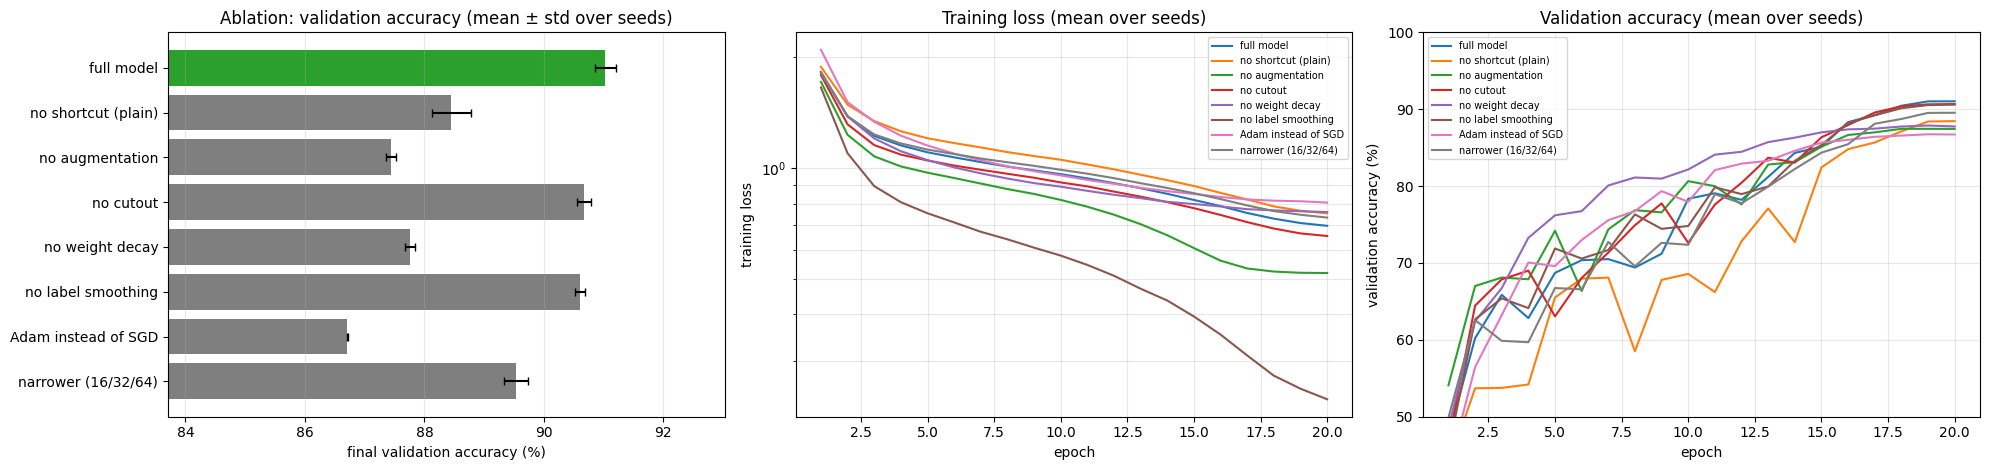

In [16]:
def stk(name, key): return np.array([abl[(name, s)][key] for s in ABL_SEEDS], dtype=float)      # (seeds, epochs)
full_acc = stk('full model', 'va_acc')[:, -1]
print(f"{'variant':<22}{'params':>9}{'val acc (%)':>17}{'change vs full':>16}{'final train loss':>18}{'best-epoch val acc':>20}")
rows = []
for name in VARIANTS:
    acc = stk(name, 'va_acc')[:, -1]; trl = np.nanmean(stk(name, 'tr_loss')[:, -1]); best = stk(name, 'va_acc').max(1).mean()
    rows.append((name, acc.mean(), acc.std()))
    print(f"{name:<22}{abl[(name, ABL_SEEDS[0])]['params']:>9,}{acc.mean():>9.2f} ± {acc.std():<5.2f}{acc.mean() - full_acc.mean():>+16.2f}{trl:>18.4f}{best:>20.2f}")

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
names = [r[0] for r in rows]; means = [r[1] for r in rows]; stds = [r[2] for r in rows]
ax[0].barh(range(len(rows)), means, xerr=stds, color=['tab:green'] + ['tab:gray'] * (len(rows) - 1), capsize=3)
ax[0].set_yticks(range(len(rows))); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
ax[0].set(xlim=(min(means) - 3, max(means) + 2), xlabel='final validation accuracy (%)', title='Ablation: validation accuracy (mean ± std over seeds)')
cmap = plt.get_cmap('tab10')
for k, name in enumerate(VARIANTS):
    ax[1].plot(np.arange(1, MAX_EPOCHS + 1), np.nanmean(stk(name, 'tr_loss'), 0), color=cmap(k), label=name)
    ax[2].plot(np.arange(1, MAX_EPOCHS + 1), np.nanmean(stk(name, 'va_acc'), 0), color=cmap(k), label=name)
ax[1].set(xlabel='epoch', ylabel='training loss', yscale='log', title='Training loss (mean over seeds)')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy (mean over seeds)', ylim=(50, 100))
for a in ax[1:]: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
ax[0].grid(alpha=.3, axis='x')
plt.tight_layout(); plt.show()

Final model: ResNet-20, widths (20, 40, 80), 420,670 parameters (limit 500,000), 20 epochs, lr=0.1, wd=0.001, flip+crop, cutout 8px, label smoothing 0.1
Validation accuracy of this model: 91.20%
TEST accuracy (evaluated once): 90.37%   test loss 0.3417

Per-class test accuracy:
  airplane    91.30%
  automobile  95.80%
  bird        88.40%
  cat         78.20%
  deer        90.70%
  dog         84.40%
  frog        93.30%
  horse       92.80%
  ship        95.10%
  truck       93.70%


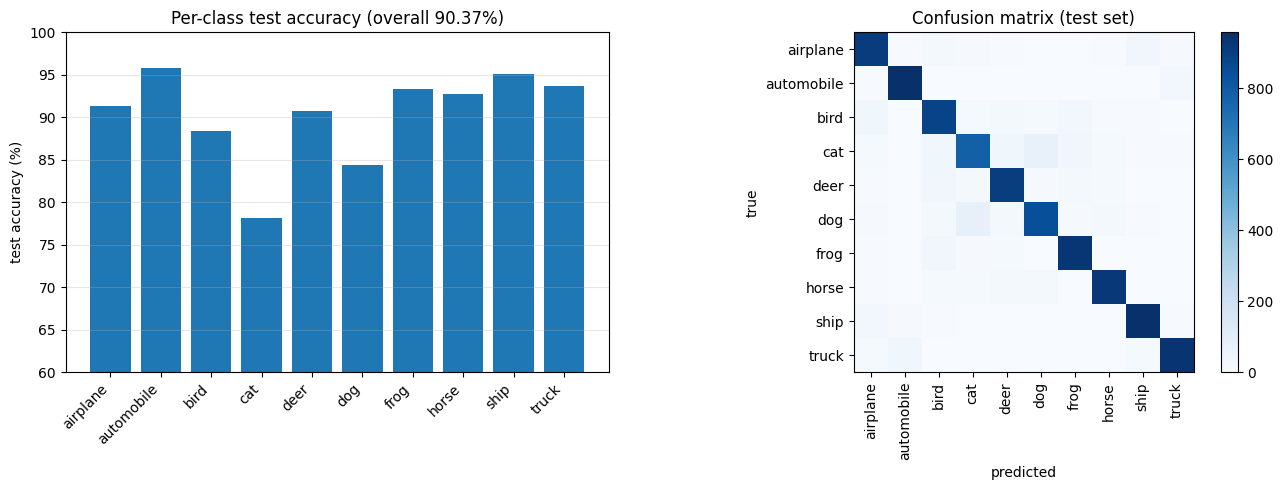

In [17]:
assert not globals().get('TEST_DONE', False), 'The test set has already been evaluated once in this session. Do not run this cell again.'

# 1) choose the final model by VALIDATION accuracy among the full-model runs
final_seed = max(ABL_SEEDS, key=lambda s: abl[('full model', s)]['va_acc'][-1])
final_model = ResNetW(FINAL['n'], FINAL['widths'], FINAL['residual']).to(device).to(memory_format=torch.channels_last)
final_model.load_state_dict(full_sd[final_seed]); final_model.eval()
n_par = count_params(final_model); assert n_par <= MAX_PARAMS
val_acc_final = abl[('full model', final_seed)]['va_acc'][-1]

# 2) load the test set (same normalisation statistics as the training split) and evaluate in ONE pass
test_raw = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
X_te = torch.from_numpy(test_raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()
y_te = torch.tensor(test_raw.targets, dtype=torch.long)
X_te, y_te = ((X_te - mean) / std).to(device), y_te.to(device)
with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
    logits = torch.cat([final_model(X_te[i:i + 1000].contiguous(memory_format=torch.channels_last)).float() for i in range(0, len(X_te), 1000)])
TEST_DONE = True                                                      # from here on the cell is locked

pred = logits.argmax(1)
test_acc = 100.0 * (pred == y_te).float().mean().item()
test_loss = F.cross_entropy(logits, y_te).item()
conf = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(y_te.cpu(), pred.cpu()): conf[t, p] += 1
per_class = 100.0 * conf.diag().float() / conf.sum(1).float()

print(f'Final model: ResNet-20, widths {FINAL["widths"]}, {n_par:,} parameters (limit {MAX_PARAMS:,}), {MAX_EPOCHS} epochs, '
      f'lr={FINAL["lr"]:g}, wd={FINAL["wd"]:g}, flip+crop, cutout {FINAL["cutout"]}px, label smoothing {FINAL["ls"]}')
print(f'Validation accuracy of this model: {val_acc_final:.2f}%')
print(f'TEST accuracy (evaluated once): {test_acc:.2f}%   test loss {test_loss:.4f}')
print('\nPer-class test accuracy:')
for c, a in zip(test_raw.classes, per_class.tolist()): print(f'  {c:<11}{a:6.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(range(10), per_class.numpy(), color='tab:blue'); ax[0].set_xticks(range(10)); ax[0].set_xticklabels(test_raw.classes, rotation=45, ha='right')
ax[0].set(ylabel='test accuracy (%)', title=f'Per-class test accuracy (overall {test_acc:.2f}%)', ylim=(60, 100)); ax[0].grid(alpha=.3, axis='y')
im = ax[1].imshow(conf.numpy(), cmap='Blues'); ax[1].set_xticks(range(10)); ax[1].set_yticks(range(10))
ax[1].set_xticklabels(test_raw.classes, rotation=90); ax[1].set_yticklabels(test_raw.classes)
ax[1].set(xlabel='predicted', ylabel='true', title='Confusion matrix (test set)'); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()